In [3]:
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/impport_packages.ipynb"    #import all necessary packages - numpy, pandas etc
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/simulation_class.ipynb"    #import all necessary packages - numpy, pandas etc
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/create_world.ipynb"

In [14]:

folder = Path("/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/finegrain_100_100_env/wo_stdfitness/epi")

epi_obj = {}

for path in folder.glob("*.csv"):
    print(path)

    # extract dimension from filename
    match = re.search(r"dims(\d+)", path.stem)
    if match:
        dim = int(match.group(1))

        df = pd.read_csv(path).iloc[:, 1:]  # remove first column
        epi_obj[f"epi_{dim}"] = df


print(epi_obj.keys())

folder = Path("/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/finegrain_100_100_env/wo_stdfitness/onlygen")

onlygen_obj = {}

for path in folder.glob("*.csv"):
    print(path)

    match = re.search(r"dims(\d+)", path.stem)
    if match:
        dim = int(match.group(1))

        df = pd.read_csv(path).iloc[:, 1:]
        onlygen_obj[f"gen_{dim}"] = df


print(onlygen_obj.keys())

dims = [1,2,3,5,10,20,35]

/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/finegrain_100_100_env/wo_stdfitness/epi/rhos100_ms100_gens10000_dims3_mutrate0.001.csv
/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/finegrain_100_100_env/wo_stdfitness/epi/rhos100_ms100_gens10000_dims20_mutrate0.001.csv
/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/finegrain_100_100_env/wo_stdfitness/epi/rhos100_ms100_gens10000_dims1_mutrate0.001.csv
/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/finegrain_100_100_env/wo_stdfitness/epi/rhos100_ms100_gens10000_dims35_mutrate0.001.csv
/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/finegrain_100_100_env/wo_stdfitness/epi/rhos100_ms100_gens10

In [13]:

folder = Path("/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/opposite_optima/epi")

# Group paths by dimension first
dim_paths = {}
for path in folder.glob("*.csv"):
    match = re.search(r"dims(\d+)", path.stem)
    if match:
        dim = int(match.group(1))
        dim_paths.setdefault(dim, []).append(path)

# Load and concat per dimension
epi_obj_opp = {}
for dim, paths in dim_paths.items():
    dfs = [pd.read_csv(p) for p in paths]
    epi_obj_opp[f"epi_{dim}"] = pd.concat(dfs, ignore_index=True)

print(list(epi_obj_opp.keys()))

folder = Path("/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/opposite_optima/onlygen")

# Group paths by dimension first
dim_paths = {}
for path in folder.glob("*.csv"):
    match = re.search(r"dims(\d+)", path.stem)
    if match:
        dim = int(match.group(1))
        dim_paths.setdefault(dim, []).append(path)

# Load and concat per dimension
onlygen_obj_opp = {}
for dim, paths in dim_paths.items():
    dfs = [pd.read_csv(p) for p in paths]
    onlygen_obj_opp[f"gen_{dim}"] = pd.concat(dfs, ignore_index=True)

print(list(onlygen_obj_opp.keys()))

['epi_5', 'epi_2', 'epi_1']
['gen_1', 'gen_5', 'gen_2']


In [17]:
dims=[1, 2, 5]

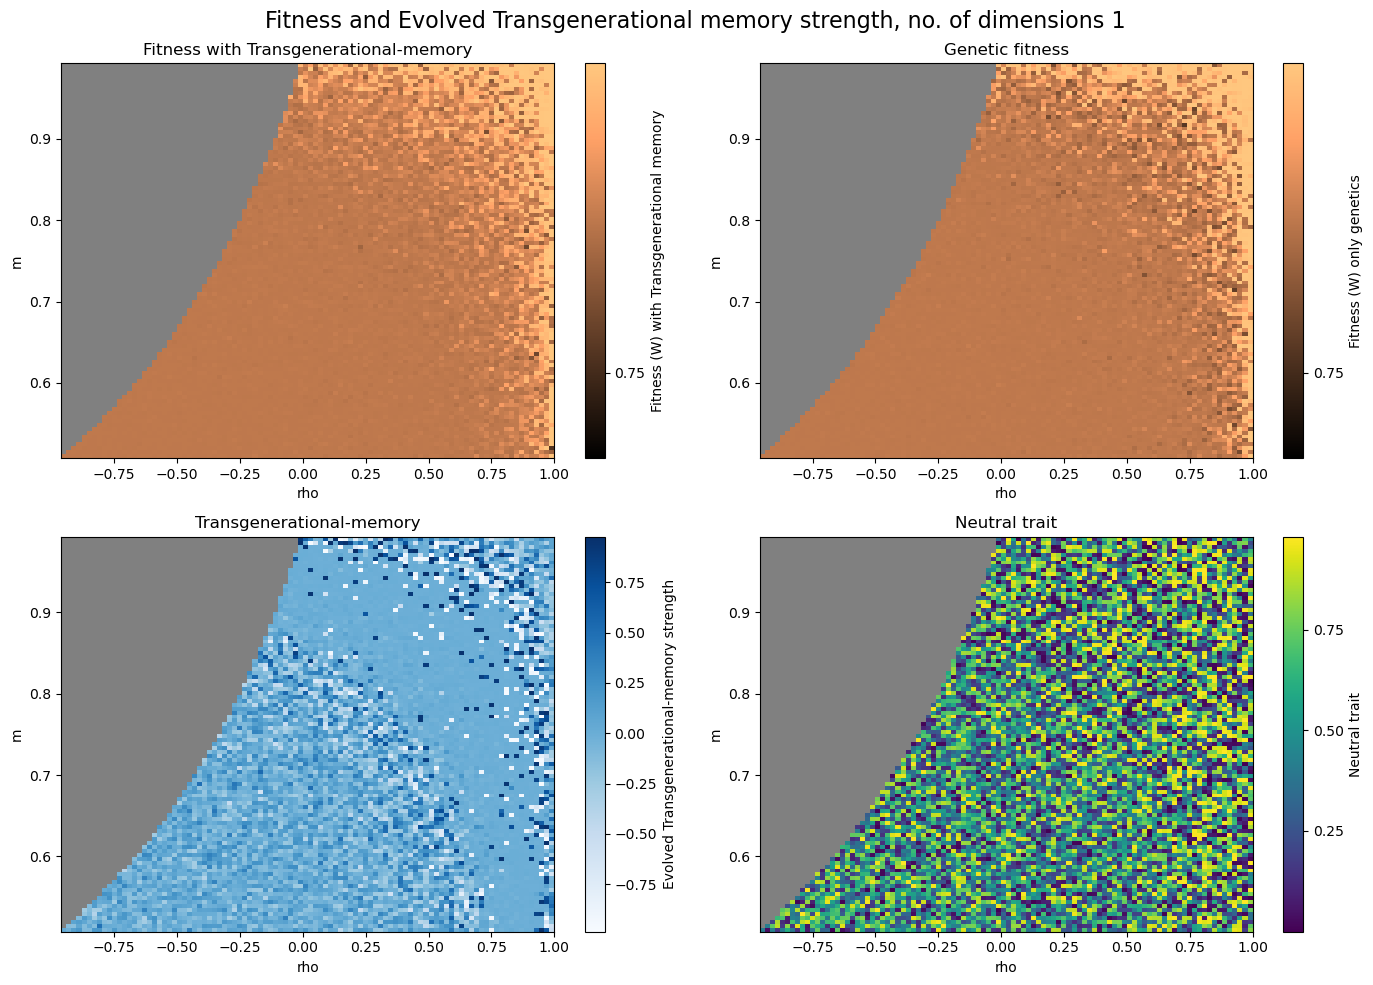

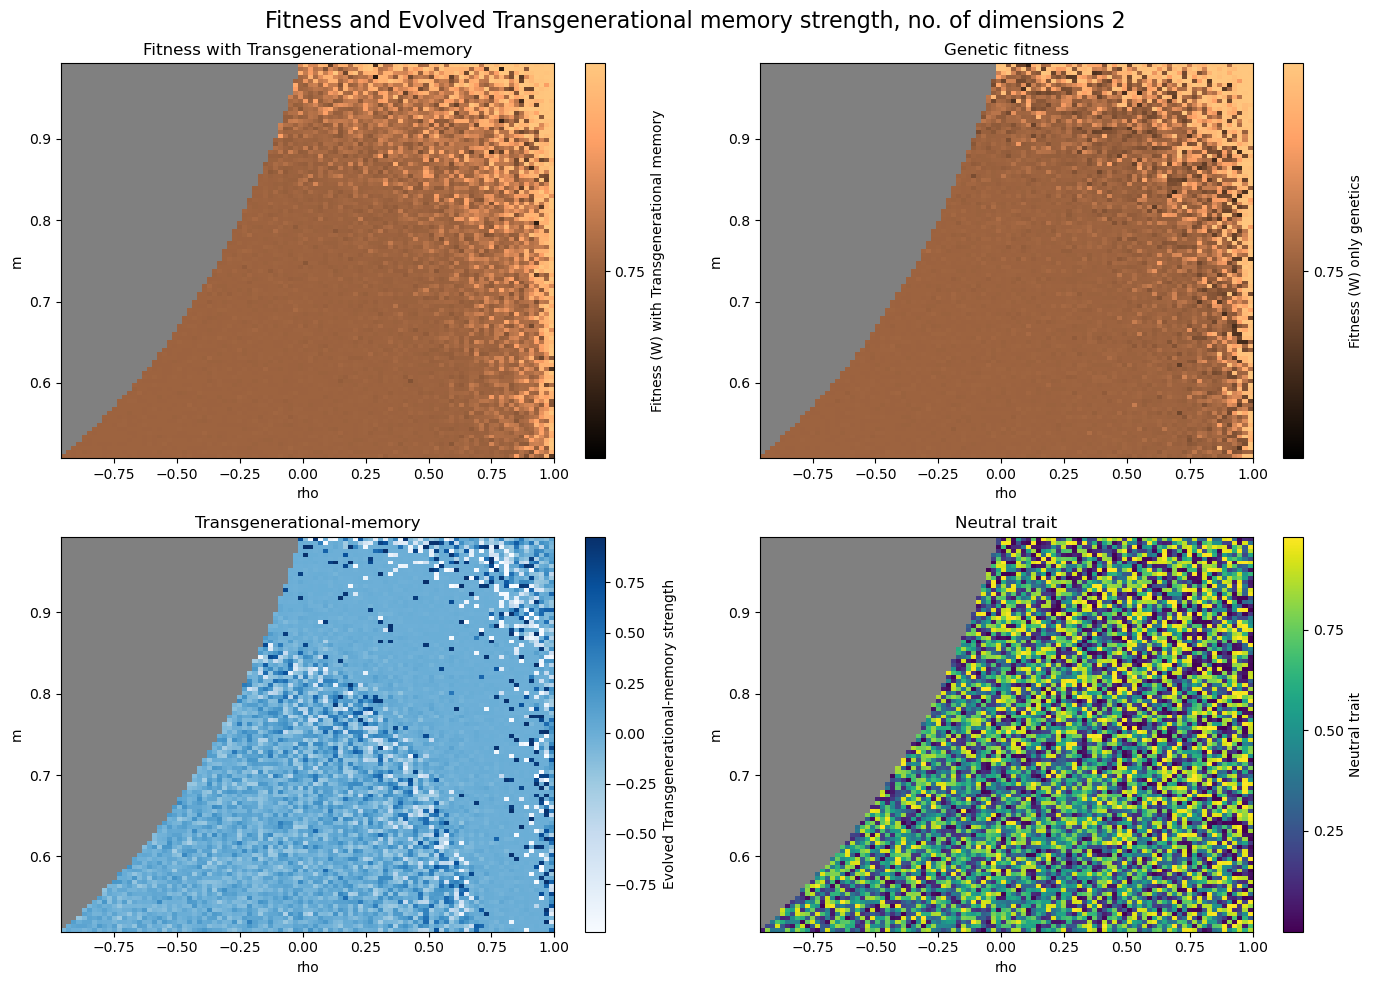

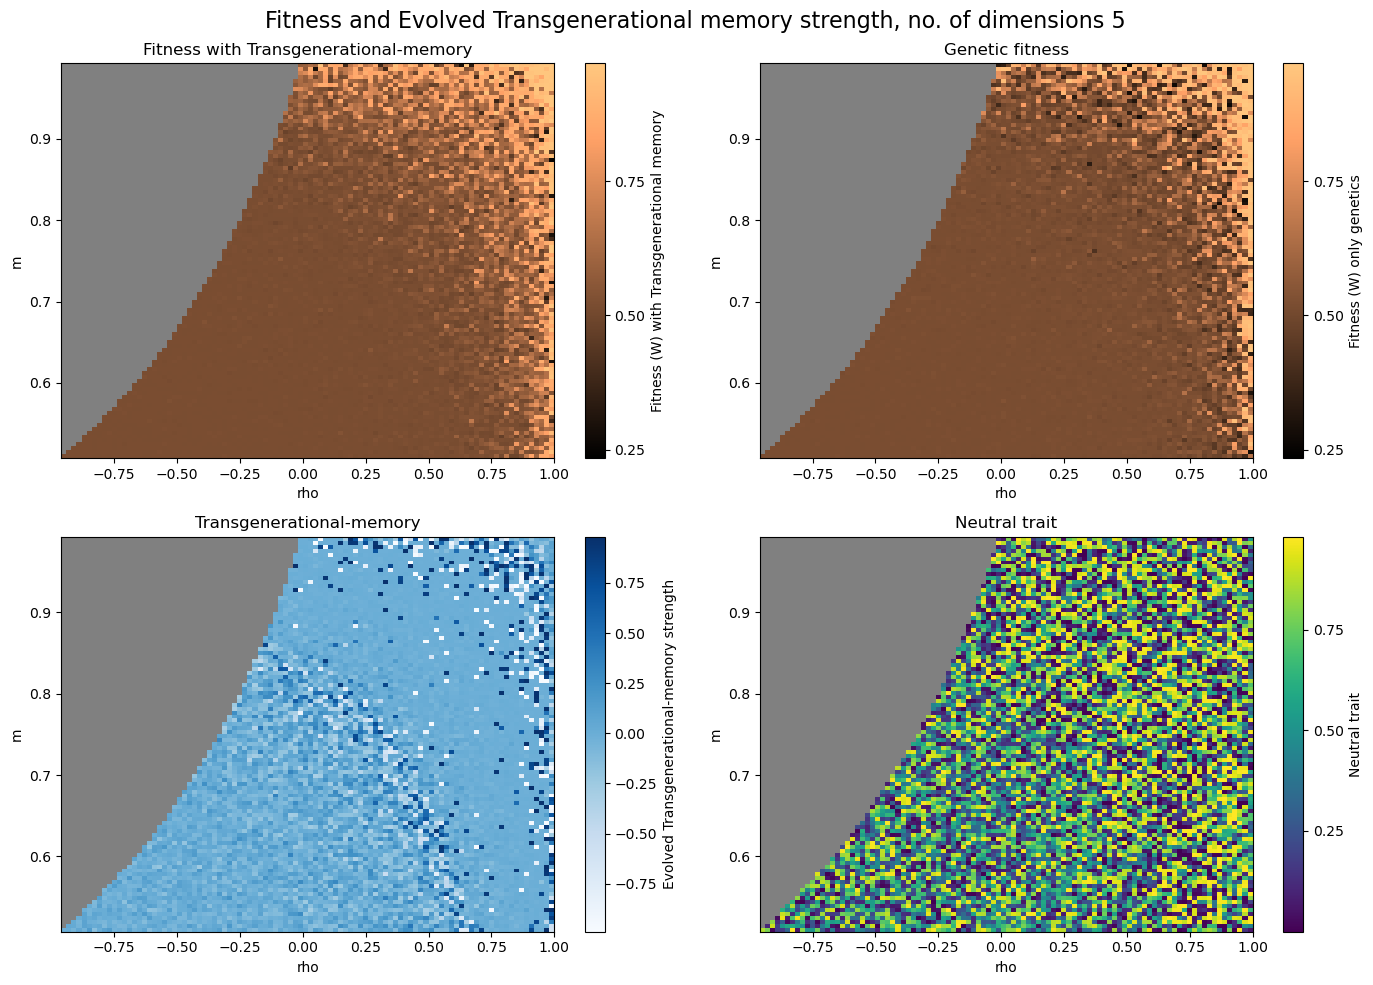

In [30]:
for i in dims:
    
    df_epi = epi_obj[f"epi_{i}"]
    df_gen = onlygen_obj[f"gen_{i}"]   # adjust key if needed
    
    df_epi_opp = epi_obj_opp[f"epi_{i}"]
    df_gen_opp = onlygen_obj_opp[f"gen_{i}"]
    
    fig, ax = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(
        f"Fitness and Evolved Transgenerational memory strength, no. of dimensions {i}",
        fontsize=16
    )
    fig.subplots_adjust(top=0.90)

    cmap1 = plt.cm.copper.copy()
    cmap1.set_bad(color='gray')

    cmap2 = plt.cm.viridis.copy()
    cmap2.set_bad(color='gray')
    
    cmap3 = plt.cm.Blues.copy()
    cmap3.set_bad(color='gray')
    # --- (0,0) fitness ---
    pivoted_fitness = df_epi.pivot_table(
        index='m', columns='rho', values='fitness'
    ).sort_index().sort_index(axis=1)
    
    
    max_abs = np.nanmax(np.abs(pivoted_fitness.values))
    min_abs = np.nanmin(np.abs(pivoted_fitness.values))
    
    norm = mcolors.Normalize(vmin=max_abs, vmax=min_abs)
    
    
    pcm1 = ax[0,0].pcolormesh(
        pivoted_fitness.columns,
        pivoted_fitness.index,
        pivoted_fitness.values,
        cmap=cmap1, norm=norm, shading='auto'
    )
    fig.colorbar(pcm1, ax=ax[0,0],
                 label='Fitness (W) with Transgenerational memory',
                 ticks=[0,0.25,0.5,0.75,1.0])

    ax[0,0].set_title(r'Fitness with Transgenerational-memory')
    ax[0,0].set_ylabel('m')
    ax[0,0].set_xlabel('rho')

    # --- (0,1) genetic fitness ---
    pivoted_gen = df_gen.pivot_table(
        index='m', columns='rho', values='fitness'
    ).sort_index().sort_index(axis=1)

    pcm2 = ax[0,1].pcolormesh(
        pivoted_gen.columns,
        pivoted_gen.index,
        pivoted_gen.values,
        cmap=cmap1, norm=norm, shading='auto'
    )
    fig.colorbar(pcm2, ax=ax[0,1],
                 label='Fitness (W) only genetics',
                 ticks=[0,0.25,0.5,0.75,1.0])

    ax[0,1].set_title('Genetic fitness')
    ax[0,1].set_ylabel('m')
    ax[0,1].set_xlabel('rho')

    # --- (1,0) epimem ---
    pivoted_epi = df_epi.pivot_table(
        index='m', columns='rho', values='epi_mem_p'
    ).sort_index().sort_index(axis=1)

    pivoted_epi_opp = df_epi_opp.pivot_table(
        index='m', columns='rho', values='epi_mem_p'
    ).sort_index().sort_index(axis=1)
    
    delta_opp =  pivoted_epi - pivoted_epi_opp
    max_abs = np.nanmax(delta_opp.values)
    min_abs = np.nanmin(delta_opp.values)
    norm_opp = mcolors.Normalize(vmin=min_abs, vmax=max_abs)
    
    pcm3 = ax[1,0].pcolormesh(
        delta_opp.columns,
        delta_opp.index,
        delta_opp.values,
        cmap=cmap3, norm= norm_opp, shading='auto'
    )
    fig.colorbar(pcm3, ax=ax[1,0],
                 label='Evolved Transgenerational-memory strength')

    ax[1,0].set_title('Transgenerational-memory')
    ax[1,0].set_ylabel('m')
    ax[1,0].set_xlabel('rho')

    # --- (1,1) neutral ---
    pivoted_neutral = df_epi.pivot_table(
        index='m', columns='rho', values='neutral_trait_p'
    ).sort_index().sort_index(axis=1)

    pcm4 = ax[1,1].pcolormesh(
        pivoted_neutral.columns,
        pivoted_neutral.index,
        pivoted_neutral.values,
        cmap=cmap2, shading='auto'
    )
    fig.colorbar(pcm4, ax=ax[1,1],
                 label='Neutral trait',
                 ticks=[0,0.25,0.5,0.75,1.0])

    ax[1,1].set_title('Neutral trait')
    ax[1,1].set_ylabel('m')
    ax[1,1].set_xlabel('rho')

    plt.tight_layout()
    #plt.savefig(f'/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Figures/finegrain_dims/dim{i}_finegrain.png')
    plt.show()

In [27]:
min_abs

np.float64(-0.9796576678155066)